# Preprocessing Dataset Retail Transactions 5500 Dirty

Notebook ini mengikuti format contoh notebook yang lu kirim, lalu disesuaikan dengan struktur dataset retail yang berbentuk **long format**: satu baris mewakili satu produk dalam satu invoice.

**Tujuan:** memeriksa kualitas data, menangani missing value dan duplikat, lalu mengubah data menjadi matriks transaksi (one-hot encoding) yang siap digunakan untuk Association Rule Mining dengan Apriori.

> Unggah file `retail_transactions_5500_dirty(2).csv` ke Google Colab sebelum menjalankan notebook ini.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

df = pd.read_csv('/content/retail_transactions_5500_dirty.csv')
print("Dataset berhasil dibaca!")

Dataset berhasil dibaca!


## 1. Menampilkan data

In [2]:
display(df.head())

,InvoiceNo,Description,Quantity
0,INV1603,Biscuits,2
1,INV1119,Wheat Flour,3
2,INV1652,Wheat Flour,5
3,INV1467,Sugar,2
4,CINV1357,Detergent,4


In [3]:
display(df.tail())

,InvoiceNo,Description,Quantity
5495,INV1526,Salt,4
5496,INV1088,Detergent,5
5497,INV1377,Bread,5
5498,CINV1068,Chocolate,3
5499,INV1406,Toothpaste,1


## 2. Melihat ukuran dan atribut dataset

In [4]:
print("Jumlah Record:", df.shape[0])
print("Jumlah Atribut:", df.shape[1])
print("\\nNama Atribut:", df.columns.tolist())
print("\\nTipe Data:")
print(df.dtypes)

Jumlah Record: 5500
Jumlah Atribut: 3
\nNama Atribut: ['InvoiceNo', 'Description', 'Quantity']
\nTipe Data:
InvoiceNo      object
Description    object
Quantity        int64
dtype: object


## 3. Menghitung jumlah data terisi

In [5]:
print("Jumlah Data Terisi Setiap Atribut:")
print(df.count())

Jumlah Data Terisi Setiap Atribut:
InvoiceNo      5500
Description    5221
Quantity       5500
dtype: int64


## 4. Memeriksa missing value

In [6]:
print("Missing Value Setiap Atribut:")
print(df.isnull().sum())

print("\\nTotal Missing Value:")
print(df.isnull().sum().sum())

Missing Value Setiap Atribut:
InvoiceNo        0
Description    279
Quantity         0
dtype: int64
\nTotal Missing Value:
279


In [7]:
missing = pd.DataFrame({
    'Jumlah Missing Value': df.isnull().sum(),
    'Persentase (%)': (df.isnull().sum() / len(df) * 100).round(2)
})
display(missing)

,Jumlah Missing Value,Persentase (%)
InvoiceNo,0,0.00
Description,279,5.07
Quantity,0,0.00


## 5. Heatmap missing value sebelum preprocessing

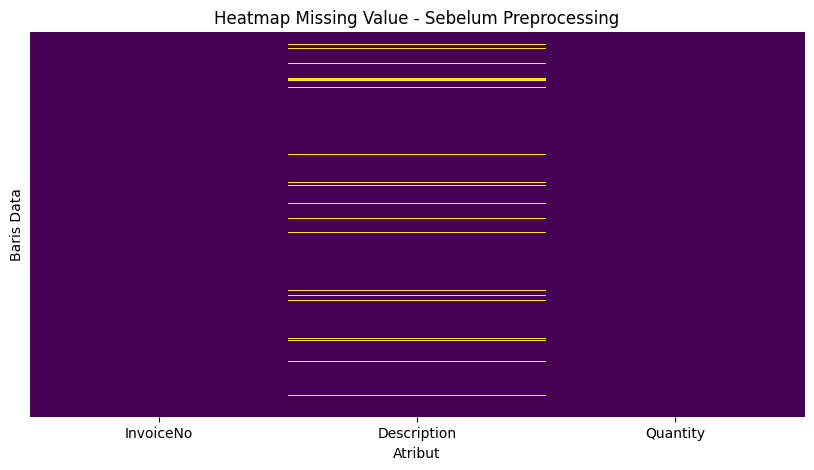

In [8]:
plt.figure(figsize=(10, 5))
sns.heatmap(df.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Heatmap Missing Value - Sebelum Preprocessing')
plt.xlabel('Atribut')
plt.ylabel('Baris Data')
plt.show()

## 6. Menangani missing value

Missing value ditemukan pada kolom `Description`. Karena nama produk yang kosong tidak dapat diketahui dengan pasti, baris tersebut dihapus. Kolom `InvoiceNo` dan `Quantity` tidak memiliki missing value.

In [9]:
df_clean = df.copy()

jumlah_missing_awal = df_clean['Description'].isnull().sum()
df_clean = df_clean.dropna(subset=['Description'])

print("Missing value Description yang dihapus:", jumlah_missing_awal)
print("Total missing value setelah penanganan:", df_clean.isnull().sum().sum())
print("Ukuran data setelah penanganan missing value:", df_clean.shape)

Missing value Description yang dihapus: 279
Total missing value setelah penanganan: 0
Ukuran data setelah penanganan missing value: (5221, 3)


## 7. Heatmap setelah menangani missing value

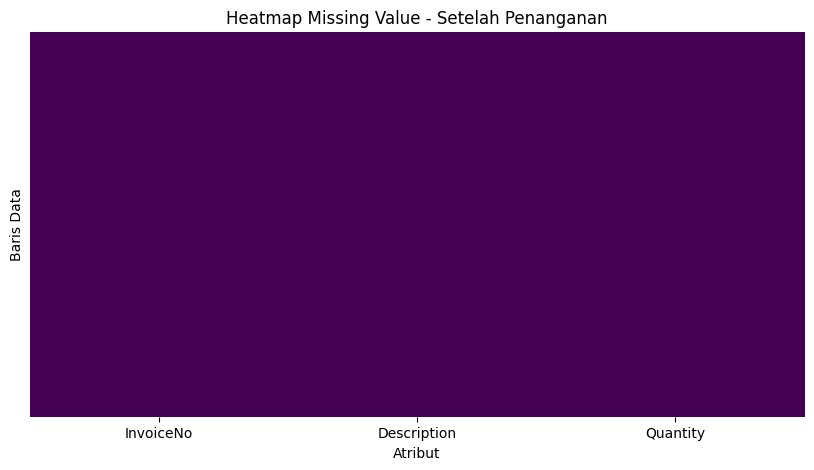

In [10]:
plt.figure(figsize=(10, 5))
sns.heatmap(df_clean.isnull(), cbar=False, cmap='viridis', yticklabels=False)
plt.title('Heatmap Missing Value - Setelah Penanganan')
plt.xlabel('Atribut')
plt.ylabel('Baris Data')
plt.show()

## 8. Memeriksa dan menangani data duplikat

Duplikat yang dihapus adalah baris yang sama persis pada seluruh kolom (`InvoiceNo`, `Description`, dan `Quantity`). Baris dengan invoice dan produk sama tetapi jumlah berbeda tidak otomatis dihapus, karena bisa merupakan catatan kuantitas terpisah. Nantinya jumlah produk per invoice akan digabungkan saat membentuk matriks transaksi.

In [11]:
jumlah_duplikat = df_clean.duplicated().sum()
print("Jumlah Data Duplikat:", jumlah_duplikat)

duplikat = df_clean[df_clean.duplicated(keep=False)].sort_values(
    by=['InvoiceNo', 'Description', 'Quantity']
)
display(duplikat.head(20))

Jumlah Data Duplikat: 109


,InvoiceNo,Description,Quantity
368,CINV1118,Eggs,4
3043,CINV1118,Eggs,4
3492,CINV1336,Jam,2
3853,CINV1336,Jam,2
4783,CINV1506,Toothpaste,3
5114,CINV1506,Toothpaste,3
3674,INV1019,Rice,4
4152,INV1019,Rice,4
2259,INV1020,Jam,5
3809,INV1020,Jam,5


In [12]:
df_clean = df_clean.drop_duplicates()

print("Jumlah duplikat setelah dihapus:", df_clean.duplicated().sum())
print("Ukuran data setelah menghapus duplikat:", df_clean.shape)

Jumlah duplikat setelah dihapus: 0
Ukuran data setelah menghapus duplikat: (5112, 3)


## 9. Memeriksa outlier pada Quantity

Outlier diperiksa menggunakan metode **Interquartile Range (IQR)** dan boxplot. Karena Quantity negatif bisa berkaitan dengan retur atau koreksi, pemeriksaan IQR dilakukan pada Quantity positif saja.

Nilai yang terdeteksi disebut kandidat outlier, bukan otomatis kesalahan. Jumlah barang yang tinggi bisa saja merupakan pembelian grosir yang valid.

In [13]:
# Statistik Quantity positif
quantity_positif = df_clean.loc[df_clean['Quantity'] > 0, 'Quantity']

Q1 = quantity_positif.quantile(0.25)
Q3 = quantity_positif.quantile(0.75)
IQR = Q3 - Q1

batas_bawah = Q1 - 1.5 * IQR
batas_atas = Q3 + 1.5 * IQR

print("Q1:", Q1)
print("Q3:", Q3)
print("IQR:", IQR)
print("Batas bawah:", batas_bawah)
print("Batas atas:", batas_atas)

outlier_mask = (
    (df_clean['Quantity'] > 0) &
    ((df_clean['Quantity'] < batas_bawah) |
     (df_clean['Quantity'] > batas_atas))
)
outlier = df_clean[outlier_mask].copy()

print("Jumlah kandidat outlier:", len(outlier))
display(outlier.head(20))

Q1: 2.0
Q3: 4.0
IQR: 2.0
Batas bawah: -1.0
Batas atas: 7.0
Jumlah kandidat outlier: 0


,InvoiceNo,Description,Quantity


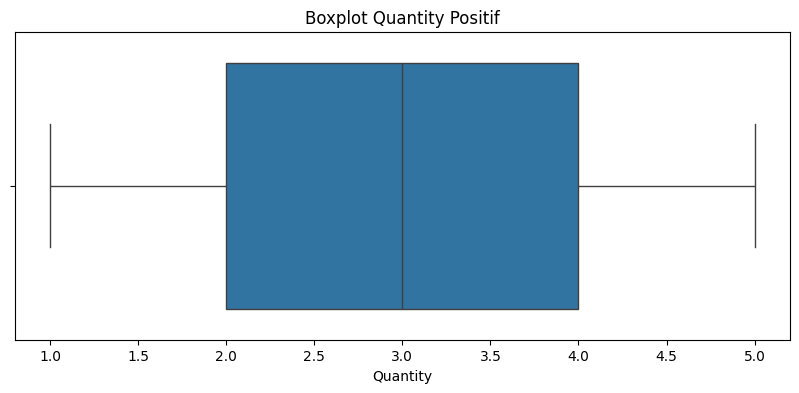

In [14]:
plt.figure(figsize=(10, 4))
sns.boxplot(x=quantity_positif)
plt.title('Boxplot Quantity Positif')
plt.xlabel('Quantity')
plt.show()

## 10. Menangani kandidat outlier

Kandidat outlier tidak langsung dihapus karena nilai Quantity yang tinggi bisa merupakan pembelian dalam jumlah besar yang valid. Untuk sementara, kandidat tersebut dipertahankan sampai ada bukti bahwa nilainya tidak valid.

In [15]:
# Kandidat outlier dipertahankan (tidak dihapus otomatis).
# Penghapusan hanya dilakukan jika sudah dipastikan data tersebut tidak valid.
HAPUS_OUTLIER = False

if HAPUS_OUTLIER:
    df_clean = df_clean.drop(index=outlier.index).copy()
    print("Kandidat outlier telah dihapus.")
else:
    print("Kandidat outlier dipertahankan untuk pemeriksaan lebih lanjut.")

print("Ukuran data setelah keputusan outlier:", df_clean.shape)

Kandidat outlier dipertahankan untuk pemeriksaan lebih lanjut.
Ukuran data setelah keputusan outlier: (5112, 3)


## 11. Memeriksa Quantity negatif

Quantity negatif tidak mewakili pembelian positif dalam keranjang belanja dan dapat menunjukkan retur atau koreksi transaksi. Untuk analisis keranjang pembelian, baris dengan `Quantity` kurang dari atau sama dengan nol dikeluarkan. Keputusan ini perlu disebutkan dalam laporan.

In [16]:
jumlah_quantity_nonpositif = (df_clean['Quantity'] <= 0).sum()
print("Baris dengan Quantity <= 0:", jumlah_quantity_nonpositif)

df_clean = df_clean[df_clean['Quantity'] > 0].copy()
print("Ukuran data setelah menyaring Quantity <= 0:", df_clean.shape)

Baris dengan Quantity <= 0: 272
Ukuran data setelah menyaring Quantity <= 0: (4840, 3)


## 12. Pemeriksaan akhir data bersih

In [17]:
print("Jumlah Record:", df_clean.shape[0])
print("Jumlah Atribut:", df_clean.shape[1])
print("Jumlah Invoice Unik:", df_clean['InvoiceNo'].nunique())
print("Jumlah Produk Unik:", df_clean['Description'].nunique())
print("Total Missing Value:", df_clean.isnull().sum().sum())
print("Jumlah Duplikat Baris:", df_clean.duplicated().sum())

Jumlah Record: 4840
Jumlah Atribut: 3
Jumlah Invoice Unik: 1169
Jumlah Produk Unik: 20
Total Missing Value: 0
Jumlah Duplikat Baris: 0


## 13. Membentuk matriks transaksi untuk Apriori

Apriori membutuhkan data berbentuk transaksi × produk. Setiap sel bernilai 1 jika produk muncul pada invoice tersebut dan 0 jika tidak. `InvoiceNo` menjadi identitas transaksi, sedangkan `Description` menjadi kolom produk.

In [18]:
basket = pd.crosstab(
    index=df_clean['InvoiceNo'],
    columns=df_clean['Description']
)

# Mengubah jumlah kemunculan menjadi nilai biner 0 dan 1
basket = (basket > 0).astype(int)

print("Ukuran Matriks Transaksi:", basket.shape)
display(basket.head())

Ukuran Matriks Transaksi: (1169, 20)


Description,Biscuits,Bread,Butter,Cheese,Chocolate,Coffee,Cooking Oil,Detergent,Eggs,Jam,Milk,Rice,Salt,Shampoo,Soap,Spices,Sugar,Tea,Toothpaste,Wheat Flour
InvoiceNo,,,,,,,,,,,,,,,,,,,,
CINV1002,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
CINV1003,0,0,0,1,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0
CINV1004,0,0,0,0,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0
CINV1008,0,0,0,0,1,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0
CINV1009,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,0,1,0,0,0


## 14. Heatmap matriks transaksi (one-hot encoding)

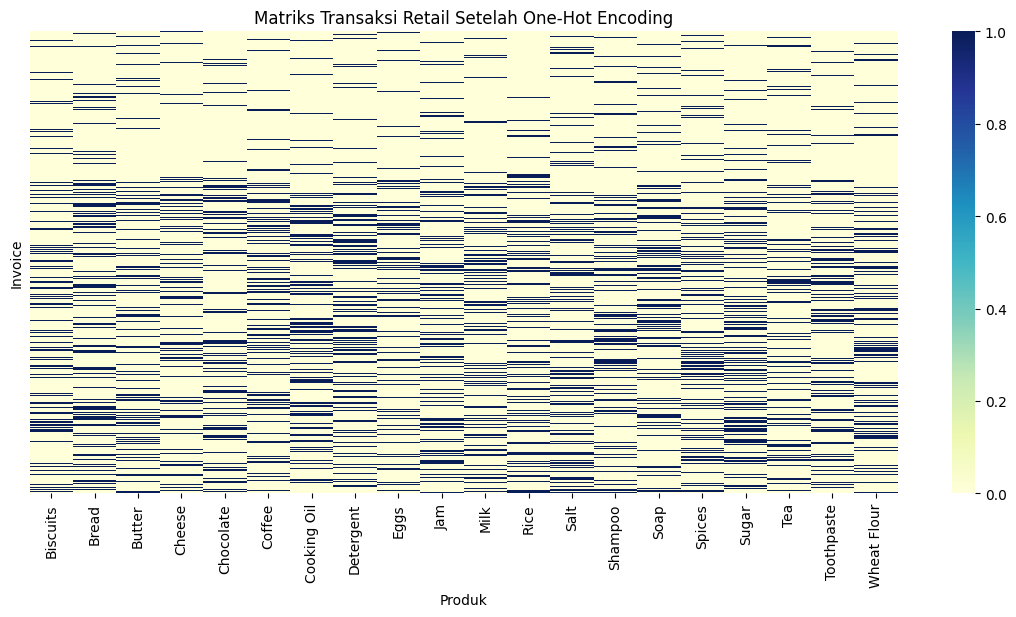

In [19]:
plt.figure(figsize=(14, 6))
sns.heatmap(basket, cmap='YlGnBu', cbar=True, yticklabels=False)
plt.title('Matriks Transaksi Retail Setelah One-Hot Encoding')
plt.xlabel('Produk')
plt.ylabel('Invoice')
plt.show()

## 15. Menyimpan hasil preprocessing

In [20]:
df_clean.to_csv('retail_transactions_clean.csv', index=False)
basket.to_csv('retail_transactions_basket.csv')

print("File berhasil disimpan:")
print("- retail_transactions_clean.csv")
print("- retail_transactions_basket.csv")

File berhasil disimpan:
- retail_transactions_clean.csv
- retail_transactions_basket.csv


## Kesimpulan

Pada notebook ini dilakukan pemeriksaan missing value, visualisasi heatmap sebelum dan sesudah penanganan, penghapusan duplikat baris yang identik, penyaringan Quantity nonpositif, dan transformasi data menjadi matriks transaksi biner.

File `retail_transactions_basket.csv` dapat digunakan sebagai input algoritma Apriori. Perlu diperhatikan bahwa penyaringan baris dan penggabungan produk dilakukan untuk menyiapkan data bagi analisis keranjang pembelian.